# LM18 Lab — Monte Carlo Simulation and the Bootstrap

Companion notebook to **From Calculus to Kelly, LM18**. It rebuilds the module's exhibits and computational examples from TR23's closes, with the seeds the module prints, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, $T$, $A$, $m$, the guarded counts and their exact recount; the case (Exhibit 1) |
| 2 | Generators: Example 1, the `Generator` object, common random numbers (the pitfall of Section 2) |
| 3 | The inverse transform: Example 2, Exhibit 2, one stream through two methods |
| 4 | The Monte Carlo estimator: Example 3, the coverage of the 95% Monte Carlo interval, Example 4, Exhibit 3 |
| 5 | Monte Carlo against quadrature: Example 5, Exhibit 4, zero hits |
| 6 | Variance reduction: Example 6, Example 7, Example 8, Exhibit 5 |
| 7 | The iid bootstrap: Example 9, Example 10, Exhibit 6, Exhibit 7 |
| 8 | Practice problems 2, 4, 5, 7, 8, 9, 11 and 12, and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv` (`date`, `price`: the closes of the TAIEX total-return index that FinMind's `TaiwanStockTotalReturnIndex` serves, 2003-01-02 → 2026-10-08). The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23: $T=5{,}849$ daily simple returns $R_t=P_t/P_{t-1}-1$ from 2003-01-03 and log returns $r_t=\ln(1+R_t)$; moments divide by $T$; $A=T/\text{years}$ with years = calendar days ÷ 365.25; five years is $m=\operatorname{round}(5A)=1{,}231$ sessions; quantiles are order statistics, `np.quantile(..., method="inverted_cdf")`. Every model of TAIEX here is fitted to all of TR23 (in-sample); a 95% Monte Carlo interval measures simulation error only.

**The seed rule.** Each simulated experiment creates its generator once, at its start, as `np.random.default_rng([e, 20261011])` with `e` the experiment's number in the module, and never reseeds it. Paths and resamples come in chunks of 500 rows (rows = paths), which are also the batches of a batch standard error. Printed simulation numbers rest on the NumPy version that `uv.lock` pins. `show(...)` prints each value next to the module's and asserts that they agree.

In [1]:
from pathlib import Path
from fractions import Fraction
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy import stats

DATA = Path("data")
SEED, CH, EPS = 20261011, 500, 1e-12
KK = 4.1074386                                   # LM5's -5% day for 0050, in standard deviations
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def rng(e):
    # the generator of experiment e: its number first, then the root seed
    return np.random.default_rng([e, SEED])


def se(y):                                       # standard error of a mean, divisor n
    return y.std() / math.sqrt(y.size)


def sd_se(y):                                    # standard error of a standard deviation
    return y.std() / math.sqrt(2 * y.size)


def bse(stat, *arrays, batches=20):              # batch standard error over 20 equal batches
    k = arrays[0].shape[0] // batches
    vals = np.array([stat(*(a[b * k:(b + 1) * k] for a in arrays)) for b in range(batches)])
    return vals.std() / math.sqrt(batches)


def show(label, value, fmt, printed):
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)

## Part 1 — Data and the case

Returns come from the closes with Polars expressions. Every count against a threshold uses the guard (`<= -x + 1e-12`, `>= x - 1e-12`) and is recounted exactly with `Fraction` on the two-decimal closes: two-decimal index levels can make a round return an exact tie (PITFALLS §5 of the repository).

In [2]:
raw = pl.read_csv(DATA / "taiex_tr.csv", try_parse_dates=True).sort("date")
tr = (raw.with_columns((pl.col("price") / pl.col("price").shift(1) - 1).alias("R"))
         .with_columns(pl.col("R").log1p().alias("r")))
ret = tr.slice(1)
T = ret.height
P = raw["price"].to_numpy()
R, r = ret["R"].to_numpy(), ret["r"].to_numpy()
dates = [d.isoformat() for d in raw["date"].to_list()]
days = (raw["date"][-1] - raw["date"][0]).days
years = days / 365.25
A = T / years
m = round(5 * A)
print(f"{P.size} closes {dates[0]} .. {dates[-1]}; first return {dates[1]}")
show("T", T, ",", "5,849")
show("years", years, ".4f", "23.7645")
show("A", A, ".2f", "246.12")
show("m = round(5A)", m, ",", "1,231")
Rbar, s, rbar, sr = R.mean(), R.std(), r.mean(), r.std()
show("Rbar, %", 100 * Rbar, ".6f", "0.062505")
show("s, %", 100 * s, ".4f", "1.2084")
show("rbar, %", 100 * rbar, ".5f", "0.05517")
show("s_r, %", 100 * sr, ".4f", "1.2107")

5850 closes 2003-01-02 .. 2026-10-08; first return 2003-01-03
T: 5,849   [book: 5,849]
years: 23.7645   [book: 23.7645]
A: 246.12   [book: 246.12]
m = round(5A): 1,231   [book: 1,231]
Rbar, %: 0.062505   [book: 0.062505]
s, %: 1.2084   [book: 1.2084]
rbar, %: 0.05517   [book: 0.05517]
s_r, %: 1.2107   [book: 1.2107]


In [3]:
counts = ret.select(
    ((pl.col("R") >= 0.03 - EPS) | (pl.col("R") <= -0.03 + EPS)).sum().alias("abs(R) >= 3%"),
    (pl.col("R") <= -0.05 + EPS).sum().alias("R <= -5%"))
print(counts)
Pq = [Fraction(f"{x:.2f}") for x in P]
Rq = [Pq[i + 1] / Pq[i] - 1 for i in range(T)]
exact = (sum(abs(x) >= Fraction(3, 100) for x in Rq), sum(x <= Fraction(-5, 100) for x in Rq))
print("exact recount with Fraction:", exact, " exact ties at +-3% or -5%:",
      sum(abs(x) == Fraction(3, 100) or x == Fraction(-5, 100) for x in Rq))
show("days with |R| >= 3%", counts.item(0, 0), "d", "175")
show("days at or below -5%", counts.item(0, 1), "d", "15")

shape: (1, 2)
┌──────────────┬──────────┐
│ abs(R) >= 3% ┆ R <= -5% │
│ ---          ┆ ---      │
│ u32          ┆ u32      │
╞══════════════╪══════════╡
│ 175          ┆ 15       │
└──────────────┴──────────┘
exact recount with Fraction: (175, 15)  exact ties at +-3% or -5%: 0
days with |R| >= 3%: 175   [book: 175]
days at or below -5%: 15   [book: 15]


Exhibit 1 windows: 4,619   [book: 4,619]
   under water: 191   [book: 191]
   share, %: 4.1   [book: 4.1]
   starts 2003-11-03 .. 2004-04-21: 116 starts in the range, 111 under water
   starts 2007-06-15 .. 2007-12-07: 122 starts in the range, 80 under water
   worst (2004-03-09 -> 2009-02-24): 0.78   [book: 0.78]
   best (2021-05-17 -> 2026-06-09): 3.43   [book: 3.43]
   disjoint five-year periods: 4.75   [book: 4.75]


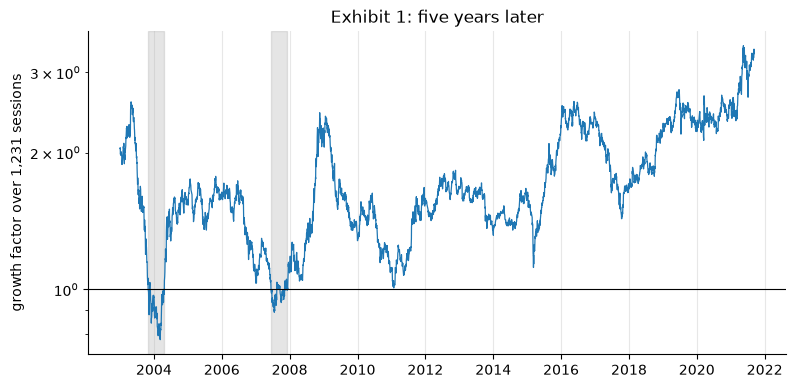

In [4]:
nwin = P.size - m
Gw = P[m:] / P[:-m]
uw = np.flatnonzero(Gw < 1)
show("Exhibit 1 windows", nwin, ",", "4,619")
show("   under water", uw.size, "d", "191")
show("   share, %", 100 * uw.size / nwin, ".1f", "4.1")
episodes = np.split(uw, np.flatnonzero(np.diff(uw) > 250) + 1)
for e in episodes:
    print(f"   starts {dates[e[0]]} .. {dates[e[-1]]}: {e[-1] - e[0] + 1} starts in the range, {e.size} under water")
i0, i1 = int(Gw.argmin()), int(Gw.argmax())
show(f"   worst ({dates[i0]} -> {dates[i0 + m]})", Gw[i0], ".2f", "0.78")
show(f"   best ({dates[i1]} -> {dates[i1 + m]})", Gw[i1], ".2f", "3.43")
show("   disjoint five-year periods", years / 5, ".2f", "4.75")
x_dates = raw["date"].to_list()[:nwin]
fig, ax = plt.subplots()
ax.plot(x_dates, Gw, lw=0.9)
for e in episodes:
    ax.axvspan(x_dates[e[0]], x_dates[e[-1]], color="grey", alpha=0.2)
ax.axhline(1, color="black", lw=0.8); ax.set_yscale("log")
ax.set_ylabel("growth factor over 1,231 sessions"); ax.set_title("Exhibit 1: five years later"); plt.show()

## Part 2 — Generators and seeds

**Example 1.** The same seed gives the same draws; another stream replicates the experiment. Then the common-random-numbers pitfall of Section 2 as an experiment (number 11): 200 repetitions of the central difference (2.11) for the slope of $\Pr(Z\le-k)$ at $k=2$, $\Delta k=0.01$, 100,000 draws a side, first with two independent arrays, then with the first array twice.

In [5]:
g = rng(1)
print(g, "| bit generator:", type(g.bit_generator).__name__)
hits = [int((rng(e).standard_normal(10_000) <= -2).sum()) for e in (1, 1, 16)]
show("Example 1 hits, [1, 20261011]", hits[0], "d", "249")
show("   rerun", hits[1], "d", "249")
show("   [16, 20261011]", hits[2], "d", "214")
p2 = stats.norm.cdf(-2)
show("   expected", 10_000 * p2, ".1f", "227.5")
show("   standard deviation of the count", math.sqrt(10_000 * p2 * (1 - p2)), ".1f", "14.9")

Generator(PCG64) | bit generator: PCG64
Example 1 hits, [1, 20261011]: 249   [book: 249]
   rerun: 249   [book: 249]
   [16, 20261011]: 214   [book: 214]
   expected: 227.5   [book: 227.5]
   standard deviation of the count: 14.9   [book: 14.9]


In [6]:
g11 = rng(11)                                    # experiment 11, created once
ind, com = np.empty(200), np.empty(200)
for i in range(200):
    a = g11.standard_normal(100_000)             # used for Pr(Z <= -2.01)
    b = g11.standard_normal(100_000)             # used for Pr(Z <= -1.99) when the draws are independent
    ind[i] = ((a <= -2.01).mean() - (b <= -1.99).mean()) / 0.02
    com[i] = ((a <= -2.01).mean() - (a <= -1.99).mean()) / 0.02
print(f"independent draws: sd {ind.std():.3f} +- {sd_se(ind):.3f}; formula 0.0333")
print(f"common draws:      sd {com.std():.4f} +- {sd_se(com):.4f}; formula 0.0052")
print(f"exact slope -phi(2) = {-stats.norm.pdf(2):.4f}; mean of the common estimates {com.mean():.4f}")

independent draws: sd 0.037 +- 0.002; formula 0.0333
common draws:      sd 0.0052 +- 0.0003; formula 0.0052
exact slope -phi(2) = -0.0540; mean of the common estimates -0.0540


## Part 3 — The inverse transform

**Example 2** and **Exhibit 2**. Waits between days with $\lvert R\rvert\ge3\%$ under an exponential model, and days drawn from $\hat F$ by the rank $\lceil Tu\rceil$. Then one stream through two methods: `norm.ppf` of experiment 2's uniforms against `standard_normal(3)` from the same stream re-created (the pitfall of Section 8).

uniforms: [0.1396965 0.4634985 0.1740834]
lambda: 0.02992   [book: 0.02992]
   wait for u = 0.1396965: 5.03   [book: 5.03]
   wait for u = 0.4634985: 20.81   [book: 20.81]
   wait for u = 0.1740834: 6.39   [book: 6.39]
   mean wait 1/lambda: 33.42   [book: 33.42]
   median wait ln2/lambda: 23.17   [book: 23.17]
ranks: [818, 2712, 1019]   T u = [817.085, 2711.003, 1018.214]
   R_(818) on 2021-12-14, %: -0.9468   [book: -0.9468]
   R_(2712) on 2007-02-01, %: +0.0247   [book: +0.0247]
   R_(1019) on 2005-09-23, %: -0.7785   [book: -0.7785]
np.quantile(R, u3, method='inverted_cdf') gives the same: [-0.94682145  0.02465186 -0.77848355]


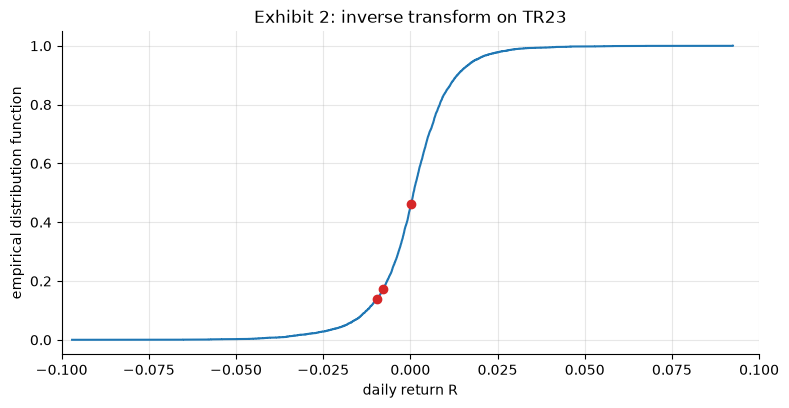

In [7]:
u3 = rng(2).random(3)
print("uniforms:", u3.round(7))
lam = 175 / T
show("lambda", lam, ".5f", "0.02992")
for u, p in zip(u3, ("5.03", "20.81", "6.39")):
    show(f"   wait for u = {u:.7f}", -math.log(1 - u) / lam, ".2f", p)
show("   mean wait 1/lambda", 1 / lam, ".2f", "33.42")
show("   median wait ln2/lambda", math.log(2) / lam, ".2f", "23.17")
Rs = np.sort(R)
ranks = [math.ceil(T * u) for u in u3]
print("ranks:", ranks, "  T u =", [round(float(T * u), 3) for u in u3])
for j, p in zip(ranks, ("-0.9468", "+0.0247", "-0.7785")):
    x = Rs[j - 1]
    show(f"   R_({j}) on {dates[1 + int(np.flatnonzero(R == x)[0])]}, %", 100 * x, "+.4f", p)
print("np.quantile(R, u3, method='inverted_cdf') gives the same:", np.quantile(R, u3, method="inverted_cdf") * 100)
fig, ax = plt.subplots()
ax.step(Rs, np.arange(1, T + 1) / T, where="post")
ax.scatter([Rs[j - 1] for j in ranks], u3, color="tab:red", zorder=3)
ax.set_xlim(-0.1, 0.1); ax.set_xlabel("daily return R"); ax.set_ylabel("empirical distribution function")
ax.set_title("Exhibit 2: inverse transform on TR23"); plt.show()

In [8]:
for x, p in zip(stats.norm.ppf(u3), ("-1.0817", "-0.0916", "-0.9382")):
    show("norm.ppf(u)", x, ".4f", p)
for x, p in zip(rng(2).standard_normal(3), ("0.1679", "0.2891", "0.7095")):
    show("standard_normal(3), default_rng([2, 20261011]) re-created", x, ".4f", p)

norm.ppf(u): -1.0817   [book: -1.0817]
norm.ppf(u): -0.0916   [book: -0.0916]
norm.ppf(u): -0.9382   [book: -0.9382]
standard_normal(3), default_rng([2, 20261011]) re-created: 0.1679   [book: 0.1679]
standard_normal(3), default_rng([2, 20261011]) re-created: 0.2891   [book: 0.2891]
standard_normal(3), default_rng([2, 20261011]) re-created: 0.7095   [book: 0.7095]


## Part 4 — The Monte Carlo estimator

**Example 3.** The case's model: iid normal daily log returns with $g=\bar r$ and $\sigma_r=s_r$. The exact answer is $\Phi(-g\sqrt m/\sigma_r)$; experiment 3 simulates 10,000 paths in 20 chunks of 500 rows. Then the **coverage** of the 95% Monte Carlo interval (experiment 13): 1,000 runs of $n=1{,}000$ paths, with $\ln G$ drawn directly from its exact law $\mathcal N(m\bar r,ms_r^2)$, count how many intervals cover 5.49%. With about 55 hits a run the normal approximation is rough, so compare with the exact binomial coverage.

In [9]:
p_ln = stats.norm.cdf(-math.sqrt(m) * rbar / sr)
show("Example 3 exact Pr(G<1), %", 100 * p_ln, ".2f", "5.49")
g3 = rng(3)
lnG3 = np.empty(10_000)
for c in range(0, 10_000, CH):
    lnG3[c:c + CH] = (rbar + sr * g3.standard_normal((CH, m))).sum(axis=1)
Y3 = (lnG3 < 0).astype(float)
show("   paths under water", int(Y3.sum()), "d", "530")
show("   estimate", Y3.mean(), ".4f", "0.0530")
show("   standard error", se(Y3), ".4f", "0.0022")
print(f"   95% Monte Carlo interval {Y3.mean() - 1.96 * se(Y3):.4f} .. {Y3.mean() + 1.96 * se(Y3):.4f}")

Example 3 exact Pr(G<1), %: 5.49   [book: 5.49]
   paths under water: 530   [book: 530]
   estimate: 0.0530   [book: 0.0530]
   standard error: 0.0022   [book: 0.0022]
   95% Monte Carlo interval 0.0486 .. 0.0574


In [10]:
g13 = rng(13)
cover = 0
for _ in range(1000):
    y = (m * rbar + math.sqrt(m) * sr * g13.standard_normal(1000) < 0).astype(float)
    cover += abs(y.mean() - p_ln) <= 1.96 * se(y)
xs = np.arange(1001)
ph = xs / 1000
inside = np.abs(ph - p_ln) <= 1.96 * np.sqrt(ph * (1 - ph) / 1000)
c_exact = stats.binom.pmf(xs, 1000, p_ln)[inside].sum()
print(f"coverage: {cover} of 1,000 intervals cover {p_ln:.4f} (standard error of the count "
      f"{math.sqrt(1000 * c_exact * (1 - c_exact)):.0f}); exact binomial coverage {100 * c_exact:.1f}%; "
      f"expected hits a run {1000 * p_ln:.0f}")

coverage: 937 of 1,000 intervals cover 0.0549 (standard error of the count 7); exact binomial coverage 94.4%; expected hits a run 55


**Example 4** with LM12's printed S5 factor $L$ typed in (% a day ÷ 100) and LM12's lab draws, `default_rng(20261011)` (that lab's seed; LM12's lab coloured them with the unrounded factor, and both give 0.0250), then **Exhibit 3** (experiment 12): 200 runs at each of six sizes against the formula (18.4).

Example 4 relative Frobenius gap: 0.0250   [book: 0.0250]
   Semiconductor variance too high, %: 4.18   [book: 4.18]
   tr(Sigma)^2 / |Sigma|_F^2: 2.6509   [book: 2.6509]
   (18.4) at n = 4,382: 0.0289   [book: 0.0289]
Exhibit 3 RMS at 4,382: 0.0301   [book: 0.0301]
   its batch standard error: 0.0007   [book: 0.0007]
   runs at or below LM12's gap: 82   [book: 82]


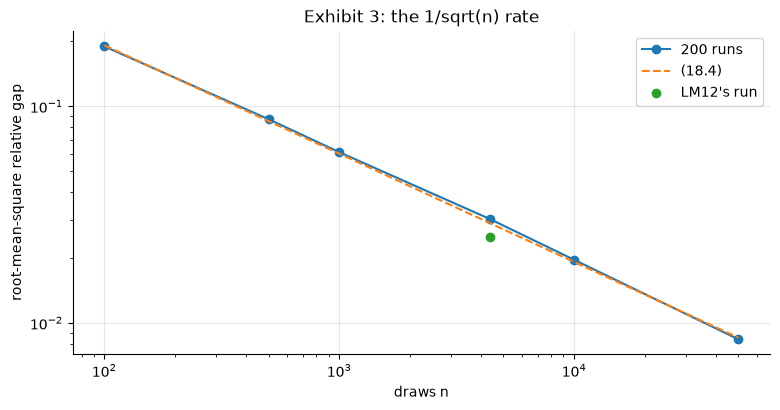

In [11]:
L = np.array([[1.5243, 0, 0, 0, 0], [0.6998, 0.9960, 0, 0, 0], [0.4336, 0.4779, 0.8594, 0, 0],
              [0.7238, 0.5162, 0.1831, 1.3034, 0], [0.6415, 0.5995, 0.2050, 0.1109, 1.4358]]) / 100
Sig = L @ L.T
sim = np.random.default_rng(20261011).standard_normal((4382, 5)) @ L.T   # row t is L z_t
S_sim = np.cov(sim, rowvar=False, ddof=0)
gap = np.linalg.norm(S_sim - Sig) / np.linalg.norm(Sig)
show("Example 4 relative Frobenius gap", gap, ".4f", "0.0250")
show("   Semiconductor variance too high, %", 100 * (S_sim[0, 0] / Sig[0, 0] - 1), ".2f", "4.18")
ratio = np.trace(Sig) ** 2 / np.linalg.norm(Sig) ** 2
show("   tr(Sigma)^2 / |Sigma|_F^2", ratio, ".4f", "2.6509")
show("   (18.4) at n = 4,382", math.sqrt((1 + ratio) / 4382), ".4f", "0.0289")
g12 = rng(12)
sizes = (100, 500, 1000, 4382, 10_000, 50_000)
rms, runs4382 = [], None
for n in sizes:
    gs = np.array([np.linalg.norm(np.cov(g12.standard_normal((n, 5)) @ L.T, rowvar=False, ddof=0) - Sig)
                   / np.linalg.norm(Sig) for _ in range(200)])
    rms.append(math.sqrt((gs ** 2).mean()))
    if n == 4382:
        runs4382 = gs
        show("Exhibit 3 RMS at 4,382", rms[-1], ".4f", "0.0301")
        show("   its batch standard error", bse(lambda a: math.sqrt((a ** 2).mean()), gs), ".4f", "0.0007")
show("   runs at or below LM12's gap", int((runs4382 <= gap).sum()), "d", "82")
fig, ax = plt.subplots()
ax.loglog(sizes, rms, marker="o", label="200 runs")
ax.loglog(sizes, [math.sqrt((1 + ratio) / n) for n in sizes], ls="--", label="(18.4)")
ax.scatter([4382], [gap], color="tab:green", zorder=3, label="LM12's run")
ax.set_xlabel("draws n"); ax.set_ylabel("root-mean-square relative gap"); ax.legend()
ax.set_title("Exhibit 3: the 1/sqrt(n) rate"); plt.show()

## Part 5 — Monte Carlo against quadrature

**Example 5** (experiment 5) and **Exhibit 4**: LM5's printed Simpson errors divided by the exact $2.000355\times10^{-5}$, against the relative standard errors of plain Monte Carlo and of importance sampling. Then the zero-hit pitfall: how often does a plain run of 10,000 draws see no hit at all?

Example 5 hits in 10^6 draws: 18   [book: 18]
   estimate x 1e5: 1.8   [book: 1.8]
   standard error x 1e5: 0.4   [book: 0.4]
   relative standard error per draw: 223.6   [book: 223.6]


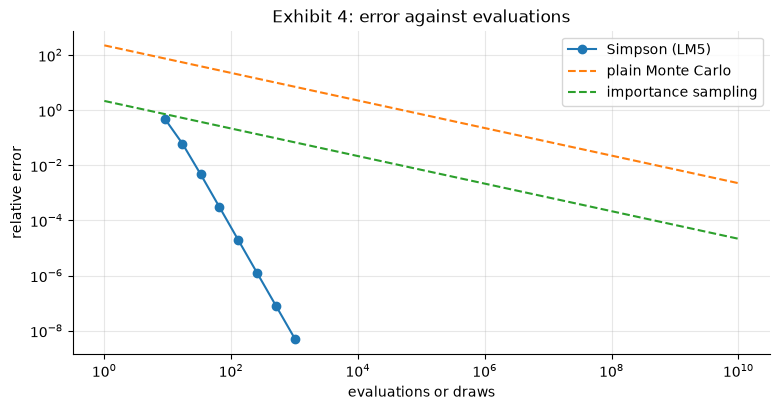

zero hits in 10,000 plain draws: (1-p)^10000: 0.8187   [book: 0.8187]


In [12]:
pk = stats.norm.cdf(-KK)
z5 = rng(5).standard_normal(10 ** 6)
h5 = int((z5 <= -KK).sum())
show("Example 5 hits in 10^6 draws", h5, "d", "18")
show("   estimate x 1e5", h5 / 1e6 * 1e5, ".1f", "1.8")
show("   standard error x 1e5", math.sqrt(h5 / 1e6 * (1 - h5 / 1e6) / 1e6) * 1e5, ".1f", "0.4")
show("   relative standard error per draw", math.sqrt((1 - pk) / pk), ".1f", "223.6")
var_is = math.exp(KK ** 2) * stats.norm.cdf(-2 * KK) - pk ** 2
simpson = {8: 9.69e-6, 16: 1.23e-6, 32: 9.47e-8, 64: 6.23e-9, 128: 3.94e-10, 256: 2.47e-11, 512: 1.55e-12,
           1024: 9.67e-14}                          # LM5's printed Simpson errors, by panels
n_mc = np.logspace(0, 10, 50)
fig, ax = plt.subplots()
ax.loglog([n + 1 for n in simpson], [e / 2.000355e-5 for e in simpson.values()], marker="o", label="Simpson (LM5)")
ax.loglog(n_mc, math.sqrt((1 - pk) / pk) / np.sqrt(n_mc), ls="--", label="plain Monte Carlo")
ax.loglog(n_mc, math.sqrt(var_is) / pk / np.sqrt(n_mc), ls="--", label="importance sampling")
ax.set_xlabel("evaluations or draws"); ax.set_ylabel("relative error"); ax.legend()
ax.set_title("Exhibit 4: error against evaluations"); plt.show()
show("zero hits in 10,000 plain draws: (1-p)^10000", (1 - pk) ** 10_000, ".4f", "0.8187")

## Part 6 — Variance reduction

**Example 6** (experiment 6, 5,000 antithetic pairs), **Example 7** (the paths of experiment 3 with $\ln G$ as a control) and **Example 8** (experiment 8, a shift of $a=k$), collected in **Exhibit 5**.

In [13]:
v = m * sr ** 2
G3 = np.exp(lnG3)
show("Example 6 E G", math.exp(m * (rbar + sr ** 2 / 2)), ".4f", "2.1584")
g6 = rng(6)
Sa, Sb = np.empty(5000), np.empty(5000)
for c in range(0, 5000, CH):
    Z = g6.standard_normal((CH, m))
    Sa[c:c + CH] = (rbar + sr * Z).sum(axis=1)
    Sb[c:c + CH] = (rbar - sr * Z).sum(axis=1)
pairG = (np.exp(Sa) + np.exp(Sb)) / 2
pairI = ((Sa < 0).astype(float) + (Sb < 0)) / 2
show("   antithetic E G", pairG.mean(), ".3f", "2.155")
show("   its standard error", se(pairG), ".3f", "0.004")
show("   plain E G (experiment 3)", G3.mean(), ".3f", "2.165")
show("   its standard error", se(G3), ".3f", "0.010")
show("   rho_- = -exp(-m s_r^2)", -math.exp(-v), ".3f", "-0.835")
show("   antithetic Pr(G<1)", pairI.mean(), ".4f", "0.0528")

Example 6 E G: 2.1584   [book: 2.1584]
   antithetic E G: 2.155   [book: 2.155]
   its standard error: 0.004   [book: 0.004]
   plain E G (experiment 3): 2.165   [book: 2.165]
   its standard error: 0.010   [book: 0.010]
   rho_- = -exp(-m s_r^2): -0.835   [book: -0.835]
   antithetic Pr(G<1): 0.0528   [book: 0.0528]


In [14]:
def slope(y, x):
    c = np.cov(y, x, ddof=0)
    return c[0, 1] / c[1, 1]


b = slope(G3, lnG3)
show("Example 7 beta hat", b, ".2f", "2.18")
show("   its batch standard error", bse(slope, G3, lnG3), ".2f", "0.01")
Gc = G3 - b * (lnG3 - m * rbar)
show("   controlled E G", Gc.mean(), ".3f", "2.161")
show("   its standard error", se(Gc), ".3f", "0.003")
show("   exact rho", math.sqrt(v / (math.exp(v) - 1)), ".3f", "0.955")
bi = slope(Y3, lnG3)
Yc = Y3 - bi * (lnG3 - m * rbar)
show("   controlled Pr(G<1)", Yc.mean(), ".4f", "0.0535")
show("   its standard error", se(Yc), ".4f", "0.0020")

Example 7 beta hat: 2.18   [book: 2.18]
   its batch standard error: 0.01   [book: 0.01]
   controlled E G: 2.161   [book: 2.161]
   its standard error: 0.003   [book: 0.003]
   exact rho: 0.955   [book: 0.955]
   controlled Pr(G<1): 0.0535   [book: 0.0535]
   its standard error: 0.0020   [book: 0.0020]


In [15]:
x8 = -KK + rng(8).standard_normal(10_000)
y8 = (x8 <= -KK) * np.exp(KK * x8 + KK ** 2 / 2)
show("Example 8 shifted draws in the tail", int((x8 <= -KK).sum()), ",", "5,043")
show("   estimate x 1e5", y8.mean() * 1e5, ".3f", "2.047")
show("   standard error x 1e5", se(y8) * 1e5, ".3f", "0.044")
show("   variance of one draw x 1e9", var_is * 1e9, ".4f", "1.8546")
show("   variance divided by", pk * (1 - pk) / var_is, ",.0f", "10,786")
vr = pl.DataFrame({
    "target": ["tail"] * 2 + ["E G"] * 3 + ["Pr(G<1)"] * 3,
    "method": ["plain", "importance sampling", "plain", "antithetic", "control", "plain", "antithetic", "control"],
    "estimate": [h5 / 1e6, y8.mean(), G3.mean(), pairG.mean(), Gc.mean(), Y3.mean(), pairI.mean(), Yc.mean()],
    "standard error": [math.sqrt(h5 / 1e6 * (1 - h5 / 1e6) / 1e6), se(y8), se(G3), se(pairG), se(Gc), se(Y3),
                       se(pairI), se(Yc)]})
vr   # Exhibit 5

Example 8 shifted draws in the tail: 5,043   [book: 5,043]
   estimate x 1e5: 2.047   [book: 2.047]
   standard error x 1e5: 0.044   [book: 0.044]
   variance of one draw x 1e9: 1.8546   [book: 1.8546]
   variance divided by: 10,786   [book: 10,786]


target,method,estimate,standard error
str,str,f64,f64
"""tail""","""plain""",0.000018,0.000004
"""tail""","""importance sampling""",0.00002,4.3658e-7
"""E G""","""plain""",2.165165,0.009702
"""E G""","""antithetic""",2.155069,0.003969
"""E G""","""control""",2.160503,0.002841
"""Pr(G<1)""","""plain""",0.053,0.00224
"""Pr(G<1)""","""antithetic""",0.0528,0.002173
"""Pr(G<1)""","""control""",0.053534,0.001972


## Part 7 — The iid bootstrap

**Example 9** (experiment 9) and **Example 10** (experiment 10) draw day indices with `integers(0, T, ...)`: each day with probability $1/T$ at every draw. **Exhibit 6** sets the four answers side by side, and **Exhibit 7** (experiment 14) shows what resampling the days destroys.

In [16]:
g9 = rng(9)
means = np.empty(10_000)
for c in range(0, 10_000, CH):
    means[c:c + CH] = R[g9.integers(0, T, size=(CH, T))].mean(axis=1)
show("Example 9 mean of the resample means, %", 100 * means.mean(), ".5f", "0.06272")
show("   standard error, %", 100 * se(means), ".5f", "0.00016")
show("   their standard deviation (divisor B), %", 100 * means.std(), ".5f", "0.01563")
show("   its standard error, %", 100 * sd_se(means), ".5f", "0.00011")
show("   exact s/sqrt(T), %", 100 * s / math.sqrt(T), ".5f", "0.01580")

Example 9 mean of the resample means, %: 0.06272   [book: 0.06272]
   standard error, %: 0.00016   [book: 0.00016]
   their standard deviation (divisor B), %: 0.01563   [book: 0.01563]
   its standard error, %: 0.00011   [book: 0.00011]
   exact s/sqrt(T), %: 0.01580   [book: 0.01580]


In [17]:
g10 = rng(10)
S10, G10 = np.empty(10_000), np.empty(10_000)
for c in range(0, 10_000, CH):
    idx = g10.integers(0, T, size=(CH, m))
    S10[c:c + CH] = r[idx].sum(axis=1)
    G10[c:c + CH] = np.prod(1 + R[idx], axis=1)
Y10 = (S10 < 0).astype(float)
show("Example 10 resamples under water", int(Y10.sum()), "d", "561")
show("   estimate", Y10.mean(), ".4f", "0.0561")
show("   standard error", se(Y10), ".4f", "0.0023")
show("   exact E G_boot = (1 + Rbar)^m", (1 + Rbar) ** m, ".4f", "2.1580")
show("   plain mean G_boot", G10.mean(), ".3f", "2.136")
show("   its standard error", se(G10), ".3f", "0.009")
C = np.cov(G10, S10, ddof=0)
show("   with ln G_boot as a control", (G10 - C[0, 1] / C[1, 1] * (S10 - m * rbar)).mean(), ".3f", "2.158")
show("   mean ln G_boot below m rbar, in standard errors", (m * rbar - S10.mean()) / se(S10), ".1f", "2.4")
q = np.quantile(G10, [0.05, 0.5, 0.95], method="inverted_cdf")
show("   quantiles 5% / 50% / 95%", " / ".join(f"{x:.2f}" for x in q), "", "0.97 / 1.94 / 3.94")
show("   standard deviation of ln G_boot", S10.std(), ".3f", "0.424")

Example 10 resamples under water: 561   [book: 561]
   estimate: 0.0561   [book: 0.0561]
   standard error: 0.0023   [book: 0.0023]
   exact E G_boot = (1 + Rbar)^m: 2.1580   [book: 2.1580]
   plain mean G_boot: 2.136   [book: 2.136]
   its standard error: 0.009   [book: 0.009]
   with ln G_boot as a control: 2.158   [book: 2.158]
   mean ln G_boot below m rbar, in standard errors: 2.4   [book: 2.4]
   quantiles 5% / 50% / 95%: 0.97 / 1.94 / 3.94   [book: 0.97 / 1.94 / 3.94]
   standard deviation of ln G_boot: 0.424   [book: 0.424]


In [18]:
qw = np.quantile(Gw, [0.05, 0.5, 0.95], method="inverted_cdf")
qn = np.exp(m * rbar + math.sqrt(m) * sr * stats.norm.ppf([0.05, 0.5, 0.95]))
four = pl.DataFrame({
    "answer": ["windows", "formula", "Monte Carlo", "bootstrap"],
    "Pr(G<1)": [uw.size / nwin, p_ln, Y3.mean(), Y10.mean()],
    "q05": [qw[0], qn[0], None, q[0]], "median": [qw[1], qn[1], None, q[1]], "q95": [qw[2], qn[2], None, q[2]],
    "sd of ln G": [np.log(Gw).std(), math.sqrt(m) * sr, None, S10.std()]})
four   # Exhibit 6

answer,Pr(G<1),q05,median,q95,sd of ln G
str,f64,f64,f64,f64,f64
"""windows""",0.041351,1.02268,1.608863,2.529011,0.283113
"""formula""",0.054937,0.98061,1.972177,3.966392,0.424791
"""Monte Carlo""",0.053,null,null,null,null
"""bootstrap""",0.0561,0.971655,1.939968,3.944535,0.423546


Exhibit 7 months: 286   [book: 286]
   monthly variance, data (divisor 286): 1.846   [book: 1.846]
   monthly variance, resamples: 0.598   [book: 0.598]
   lag-1 correlation of |r|, data: 0.161   [book: 0.161]
   lag-1 correlation of |r|, resamples: 0.0006   [book: 0.0006]


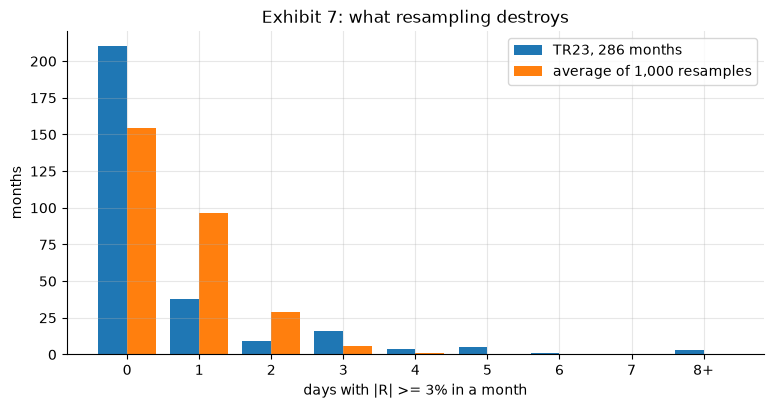

In [19]:
big = (R >= 0.03 - EPS) | (R <= -0.03 + EPS)
months = (pl.DataFrame({"month": [d[:7] for d in dates[1:]], "big": big})
            .group_by("month", maintain_order=True).agg(pl.col("big").sum().alias("n3"), pl.len().alias("days"))
            .sort("month"))
cnt = months["n3"].to_numpy()
show("Exhibit 7 months", months.height, "d", "286")
show("   monthly variance, data (divisor 286)", cnt.var(), ".3f", "1.846")
mi = np.searchsorted(months["month"].to_list(), [d[:7] for d in dates[1:]])
g14 = rng(14)
var_b, lag_b, pmf_b = np.empty(1000), np.empty(1000), np.zeros((1000, 9))
absr = np.abs(r)
for k in range(1000):
    idx = g14.integers(0, T, size=T)
    c_ = np.bincount(mi, weights=big[idx].astype(float), minlength=months.height).astype(int)
    var_b[k] = c_.var()
    pmf_b[k] = np.bincount(np.minimum(c_, 8), minlength=9)[:9]
    lag_b[k] = np.corrcoef(absr[idx][1:], absr[idx][:-1])[0, 1]
show("   monthly variance, resamples", var_b.mean(), ".3f", "0.598")
show("   lag-1 correlation of |r|, data", np.corrcoef(absr[1:], absr[:-1])[0, 1], ".3f", "0.161")
show("   lag-1 correlation of |r|, resamples", lag_b.mean(), ".4f", "0.0006")
data_pmf = np.bincount(np.minimum(cnt, 8), minlength=9)
fig, ax = plt.subplots()
ax.bar(np.arange(9) - 0.2, data_pmf, width=0.4, label="TR23, 286 months")
ax.bar(np.arange(9) + 0.2, pmf_b.mean(axis=0), width=0.4, label="average of 1,000 resamples")
ax.set_xticks(range(9), [str(i) for i in range(8)] + ["8+"]); ax.set_xlabel("days with |R| >= 3% in a month")
ax.set_ylabel("months"); ax.legend(); ax.set_title("Exhibit 7: what resampling destroys"); plt.show()

## Part 8 — Practice problems

Problems 2, 4, 5, 7, 8, 9 and 11 by computation, and Problem 12, the chunking check, in full.

In [20]:
p3 = stats.norm.cdf(-3)
show("P2 standard error x 1e5", math.sqrt(p3 * (1 - p3) / 1e6) * 1e5, ".2f", "3.67")
rets = np.array([1.2, -0.8, 0.3, -2.5, 0.6])
print("P4 draws:", [float(np.sort(rets)[math.ceil(5 * u) - 1]) for u in (0.37, 0.95, 0.18)],
      " quantile rule:", np.quantile(rets, [0.37, 0.95, 0.18], method="inverted_cdf"))
show("P5 antithetic standard error of E G", 0.0097 * math.sqrt(1 - 0.835), ".4f", "0.0039")
show("   of Pr(G<1)", 0.0022 * math.sqrt(1 - 0.058), ".4f", "0.0021")
v3 = math.exp(9) * stats.norm.cdf(-6)
show("P7 variance of one importance draw at k = 3, x 1e6", (v3 - p3 ** 2) * 1e6, ".2f", "6.17")
show("   variance divided by", p3 * (1 - p3) / (v3 - p3 ** 2), ".0f", "218")
show("P8 s/sqrt(T), %", 100 * s / math.sqrt(T), ".5f", "0.01580")
show("P9 (1 + Rbar)^m", (1 + Rbar) ** m, ".4f", "2.1580")
show("   exp(m rbar)", math.exp(m * rbar), ".4f", "1.9722")
pa, pb = stats.norm.cdf(-2.01), stats.norm.cdf(-1.99)
show("P11 central difference", (pa - pb) / 0.02, ".4f", "-0.0540")
show("   standard error, independent draws", math.sqrt((pa * (1 - pa) + pb * (1 - pb)) / 1e5) / 0.02, ".4f", "0.0333")
show("   standard error, common draws", math.sqrt((pb - pa) * (1 - (pb - pa)) / 1e5) / 0.02, ".4f", "0.0052")

P2 standard error x 1e5: 3.67   [book: 3.67]
P4 draws: [-0.8, 1.2, -2.5]  quantile rule: [-0.8  1.2 -2.5]
P5 antithetic standard error of E G: 0.0039   [book: 0.0039]
   of Pr(G<1): 0.0021   [book: 0.0021]
P7 variance of one importance draw at k = 3, x 1e6: 6.17   [book: 6.17]
   variance divided by: 218   [book: 218]
P8 s/sqrt(T), %: 0.01580   [book: 0.01580]
P9 (1 + Rbar)^m: 2.1580   [book: 2.1580]
   exp(m rbar): 1.9722   [book: 1.9722]
P11 central difference: -0.0540   [book: -0.0540]
   standard error, independent draws: 0.0333   [book: 0.0333]
   standard error, common draws: 0.0052   [book: 0.0052]


In [21]:
# P12: a fresh generator of experiment 10, twenty chunks, and one call of the same size
rng10 = np.random.default_rng([10, 20261011])
idx = np.concatenate([rng10.integers(0, T, size=(500, m)) for _ in range(20)])
G = np.prod(1 + R[idx], axis=1)
y = (G < 1).astype(float)
show("P12 Pr(G_boot < 1)", y.mean(), ".4f", "0.0561")
show("    its standard error", y.std() / 100, ".4f", "0.0023")
show("    mean G_boot", G.mean(), ".3f", "2.136")
one = np.random.default_rng([10, 20261011]).integers(0, T, size=(10_000, m))
print("one call of (10,000, m) gives identical indices:", bool((idx == one).all()))
print(f"memory of 10,000 x {m} float64 draws: {10_000 * m * 8 / 1e6:.1f} MB")
del idx, one

P12 Pr(G_boot < 1): 0.0561   [book: 0.0561]
    its standard error: 0.0023   [book: 0.0023]
    mean G_boot: 2.136   [book: 2.136]
one call of (10,000, m) gives identical indices: True
memory of 10,000 x 1231 float64 draws: 98.5 MB


### Extension: the case under a Student $t$ model

LM15 fitted a Student $t$ distribution to TR23's daily returns by maximum likelihood. Simulate the case under that model (experiment 15): 10,000 paths of 1,231 iid daily returns $R=\text{loc}+\text{scale}\cdot Y$, $Y\sim t_\nu$, with the unrounded `stats.t.fit` parameters, `standard_t(nu, size=(500, m))` twenty times. A path with a day at or below −100% is ruined and counts as under water. Compare the answer with the 5.49% of the normal model and the 5.6% of the bootstrap. Why did it move? Look at the fitted location against $\bar R$, at the mean log return the model implies, and at the size of the worst simulated days against TAIEX's daily price limit. Then rerun with the parameters rounded to the printed digits: why do the draws change, even though the seed does not?

In [22]:
nu, loc, scale = stats.t.fit(R)
print(f"maximum-likelihood t: nu {nu:.3f}, location {100 * loc:.4f}%, scale {100 * scale:.4f}% (Rbar {100 * Rbar:.4f}%)")
g15 = rng(15)
St, ruined = np.empty(10_000), 0
for c in range(0, 10_000, CH):
    Rt = loc + scale * g15.standard_t(nu, size=(CH, m))
    bad = (Rt <= -1).any(axis=1)
    ruined += int(bad.sum())
    St[c:c + CH] = np.where(bad, -np.inf, np.log1p(np.where(Rt <= -1, 0.0, Rt)).sum(axis=1))
Yt = (St < 0).astype(float)
print(f"Pr(G<1) under the t model: {100 * Yt.mean():.2f}% +- {100 * se(Yt):.2f} points; ruined paths: {ruined}")
# your code: the parameters rounded to 3.065, 0.0997% and 0.7761%; the mean log return of the model

maximum-likelihood t: nu 3.065, location 0.0997%, scale 0.7761% (Rbar 0.0625%)
Pr(G<1) under the t model: 0.86% +- 0.09 points; ruined paths: 5
